In [7]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import make_column_transformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras import layers, models, callbacks

In [2]:
wines = pd.read_csv(r"C:\Users\Admin\Desktop\Machine_Learning\Activity_2\whitewines.csv")
wines.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
ct = make_column_transformer((MinMaxScaler(), 
                                            ['fixed acidity',
                                            'volatile acidity',
                                            'citric acid',
                                            'residual sugar',
                                            'chlorides',
                                            'free sulfur dioxide',
                                            'total sulfur dioxide',
                                            'density',
                                            'pH',
                                            'sulphates',
                                            'alcohol']
                                )
                            )

X = wines.drop('quality', axis=1)
y = wines['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

ct.fit(X_train)

X_train_normal = ct.transform(X_train)
X_test_normal = ct.transform(X_test)

In [4]:
tf.random.set_seed(42)
wine_model1 = tf.keras.Sequential([
    tf.keras.layers.Dense(1)
    ])
wine_model1.compile(loss=tf.keras.losses.mae,
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    metrics=['mae'])


history = wine_model1.fit(X_train_normal, y_train, epochs=100, verbose=0)

wine_model1_loss, wine_model1_mae = wine_model1.evaluate(X_test_normal, y_test)

31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5903 - mae: 0.5903 


Text(0.5, 0, 'epochs')

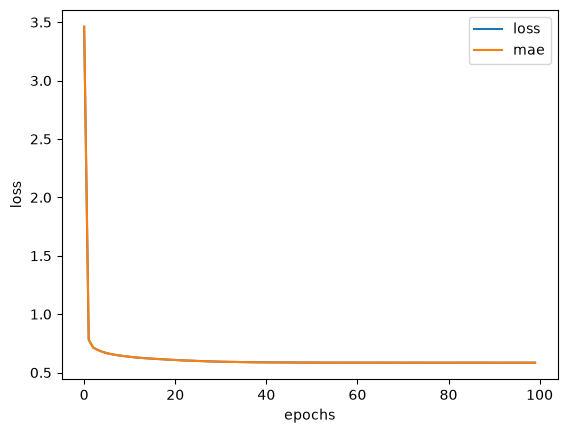

In [5]:
pd.DataFrame(history.history).plot()
plt.ylabel("loss")
plt.xlabel("epochs")

In [8]:
y_scaler = MinMaxScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

tf.random.set_seed(42)

wine_model2 = tf.keras.Sequential([
tf.keras.layers.Input(shape=(X_train_normal.shape[1],)),
tf.keras.layers.Dense(64, activation='relu'),
tf.keras.layers.Dense(32, activation='relu'),
tf.keras.layers.Dense(16, activation='relu'),
tf.keras.layers.Dense(1)
])
wine_model2.compile(loss=tf.keras.losses.mae,

optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
metrics=['mae'])

early_stop = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True)

history_2 = wine_model2.fit(X_train_normal, y_train_scaled,
                        validation_split=0.2,
                        batch_size=32,   
                        callbacks=[early_stop],
                        epochs=200,
                        verbose=0)

wine_model2_loss, wine_model2_mae = wine_model2.evaluate(X_test_normal, y_test_scaled)

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0857 - mae: 0.0857


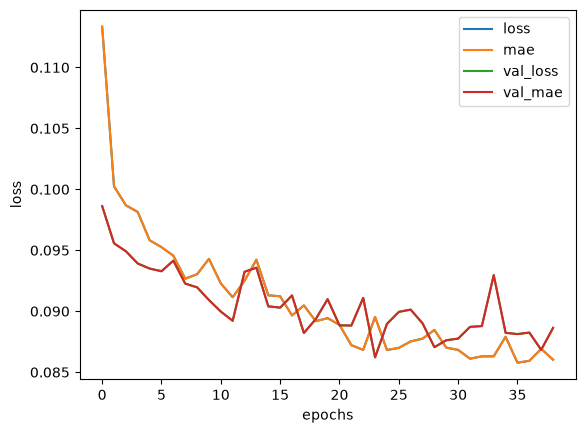

In [9]:
pd.DataFrame(history_2.history).plot()
plt.ylabel("loss")
plt.xlabel("epochs");